# Sequential Graph

In [24]:
# Setup: install the packages (already installed in .venv, safe to skip)
%pip install -q langchain langchain_core langgraph langchain_openai

Note: you may need to restart the kernel to use updated packages.


In [25]:
# Load the OpenRouter key and app settings from .env
import dotenv
import os
dotenv.load_dotenv(".env")

True

In [26]:

import dotenv
from typing import TypedDict
from urllib.parse import urlparse
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.output_parsers import StrOutputParser
from IPython.display import Image, display

In [27]:
# Main model: every LLM node uses this one unless noted
from langchain_openai import ChatOpenAI
dotenv.load_dotenv(".env")

raw_base_url = os.getenv("OPENROUTER_BASE_URL", "https://openrouter.ai/api/v1")
openrouter_base_url = raw_base_url.strip().strip('"').strip("'")
parsed = urlparse(openrouter_base_url)
if not parsed.scheme or not parsed.netloc:
    openrouter_base_url = "https://openrouter.ai/api/v1"

llm = ChatOpenAI(
    openai_api_key=os.getenv("OPENROUTER_API_KEY"),
    openai_api_base=openrouter_base_url,
    model_name="gpt-4o-mini-2024-07-18",
)


In [28]:
# ===== Pattern 1: Sequential flow =====
# Task: turn V5's messy vendor text into a size note a parent can use.
# Node 1 extracts the size info, node 2 writes the note: one node's output feeds the next.

from typing import TypedDict

# State: the raw listing in, the extracted size info, and the final note
class SizeNote(TypedDict):
    raw_listing: str
    size_info: str
    size_note: str

In [29]:
# Building blocks for every LLM call: prompt template | model | plain-string parser
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser

In [30]:
# Node 1: pull only the size information out of the raw listing
def extract_sizes(state: SizeNote) -> SizeNote:
    raw = state["raw_listing"]
    prompt = PromptTemplate(
        template="Read this vendor listing text and write the size information only, in one short sentence: {raw}",
        input_variables=["raw"]
    )

    chain = prompt | llm | StrOutputParser()
    info = chain.invoke({"raw": raw})

    state["size_info"] = info
    return state


In [31]:
# Node 2: turn the size info into 3 bullet points that help a parent pick a size
def write_size_note(state: SizeNote) -> SizeNote:
    info = state["size_info"]
    prompt = PromptTemplate(
        template="Using these size details: {info}, write 3 bullet points as markdown that help a parent choose the right size.",
        input_variables=["info"]
    )

    chain = prompt | llm | StrOutputParser()
    note = chain.invoke({"info": info})
    state["size_note"] = note
    return state

In [32]:
from langgraph.graph import StateGraph, START, END
g = StateGraph(SizeNote)

g.add_node("extract_sizes", extract_sizes)
g.add_node("write_size_note", write_size_note)

g.add_edge(START, "extract_sizes")
g.add_edge("extract_sizes", "write_size_note")
g.add_edge("write_size_note", END)

sequential_workflow = g.compile()

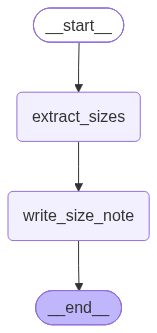

In [33]:
from IPython.display import Image, display
display(Image(sequential_workflow.get_graph().draw_mermaid_png()))

In [34]:
# Run it on one listing
initial_state = {"raw_listing": "Boys cotton dino tee. Colour: green. Tag size: 105 (CN, height in cm). Chest: 56 cm. Machine wash cold."}
final_state = sequential_workflow.invoke(initial_state)
final_state


OpenAIConnectionError: Connection error.

In [16]:
# ===== Pattern 2: Parallel flow =====
# Task: run three independent listing checks at the same time, then write one report.
# Parallel nodes return ONLY the keys they change; returning the whole state from
# three nodes in one step makes LangGraph stop with an InvalidUpdateError.

# Listing rules (illustrative)
TITLE_MAX = 60
REQUIRED_FIELDS = ["brand", "age_group", "fabric", "colour", "price"]
MIN_IMAGES = 4

In [17]:
# State: the listing, one result per check, and the final report
class ListingCheck(TypedDict):
    sku: str
    title: str
    fields: dict
    image_count: int
    title_check: dict
    fields_check: dict
    images_check: dict
    listing_report: str

In [18]:
# Check 1: title is within the character limit
def check_title(state: ListingCheck):
    n = len(state["title"])
    return {"title_check": {"ok": n <= TITLE_MAX, "detail": f"title has {n} characters (limit {TITLE_MAX})"}}

# Check 2: every required field has a value
def check_fields(state: ListingCheck):
    missing = [f for f in REQUIRED_FIELDS if not state["fields"].get(f)]
    return {"fields_check": {"ok": not missing, "detail": "all required fields present" if not missing else f"missing: {', '.join(missing)}"}}

# Check 3: enough product photos
def check_images(state: ListingCheck):
    n = state["image_count"]
    return {"images_check": {"ok": n >= MIN_IMAGES, "detail": f"{n} photos (minimum {MIN_IMAGES})"}}



# Report: runs after all checks; READY, or BLOCKED with the checks to fix
def report(state: ListingCheck):
    failed = [name for name, key in [("title", "title_check"), ("fields", "fields_check"), ("images", "images_check")]
              if not state[key]["ok"]]
    verdict = "READY for the dummy site" if not failed else f"BLOCKED, fix: {', '.join(failed)}"
    return {"listing_report": verdict}


In [19]:
graph = StateGraph(ListingCheck)

graph.add_node("check_title", check_title)
graph.add_node("check_fields", check_fields)
graph.add_node("check_images", check_images)
graph.add_node("report", report)

graph.add_edge(START, "check_title")
graph.add_edge(START, "check_fields")
graph.add_edge(START, "check_images")

graph.add_edge(["check_title", "check_fields", "check_images"], "report")
graph.add_edge("report", END)

In [20]:
parallel_workflow = graph.compile()

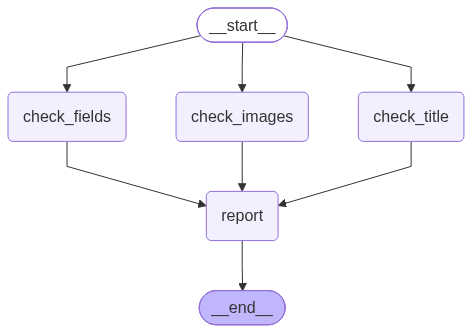

In [ ]:
# Draw the graph
display(Image(parallel_workflow.get_graph().draw_mermaid_png()))


In [21]:
# A SKU that breaks all three rules
initial_state = {
    "sku": "HS-DINO-105",
    "title": "Boys Dino Print Cotton Tee Short Sleeve Round Neck Casual Wear Green",
    "fields": {"brand": "Hopscotch", "age_group": "4-5Y", "colour": "green"},
    "image_count": 3,
}
final_state = parallel_workflow.invoke(initial_state)
final_state["listing_report"]

'BLOCKED, fix: title, fields, images'

In [22]:
# A clean SKU that passes every check
clean = {
    "sku": "HS-DINO-106",
    "title": "Boys Dino Print Cotton Tee, Green",
    "fields": {"brand": "Hopscotch", "age_group": "4-5Y", "fabric": "60% cotton, 40% polyester", "colour": "green", "price": 449},
    "image_count": 5,
}
parallel_workflow.invoke(clean)["listing_report"]

'READY for the dummy site'

In [20]:
%pip install -q langchain_community pymupdf

Note: you may need to restart the kernel to use updated packages.


In [21]:
import pymupdf

# Load the PDF into LangChain documents (one per page)
# A langchain-community 'sunset' warning here is expected; the loader still works
from langchain_community.document_loaders import PyMuPDFLoader

pdf_file_path = "V5_Vendor_Profile.pdf"

loader = PyMuPDFLoader(pdf_file_path)
documents = loader.load()

C:\Users\Kartik Gupta\AppData\Local\Temp\ipykernel_50004\1169789351.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyMuPDFLoader


In [22]:
documents[0].page_content

'HOPSCOTCH | VENDOR ONBOARDING PROFILE\nScenario document written for training. All figures are illustrative.\nVendor: V5 (kidswear: printed tees and sets)\nCountry: China\nStatus: onboarding in progress\nBUSINESS SUMMARY\nV5 is a newly onboarded vendor. It offered the lowest unit cost among\nthe vendors bidding for the pre-Diwali range and can ship 18,000 units\nin three weeks. Factory capacity is 40,000 units per month.\nSamples were approved for 2 of 3 style groups.\nDELIVERY RECORD\nPilot order: 4 of 4 shipments on time.\nPackaging and labelling quality on the pilot order: acceptable.\nONBOARDING CHECKLIST (6 steps)\n1. Legal and tax documents: DONE\n2. Factory audit: DONE\n3. Quality sample approval: DONE\n4. Size chart handoff to PPC (map vendor sizes to the Indian chart): SKIPPED\n5. Sample size audit against the Indian chart: SKIPPED\n6. Pilot order review: DONE\nNote from sales: "Skip steps 4 and 5 for now. We need this range live\nbefore the Diwali sale."\nSIZE LABELLING\nV5 

In [23]:
from typing import Annotated
import operator

class VendorState(TypedDict):
    vendor_profile: str
    strengths: str
    risks: str
    scores: Annotated[list[int], operator.add]
    decision: str

In [25]:
[4] + [7]

[4, 7]

In [26]:
# Structured output: the model must return these fields, so code can rely on them
from pydantic import BaseModel, Field

class Assessment(BaseModel):
    feedback: str = Field(description="The assessment as short bullet points")
    score: int = Field(description="Score from 0 to 10 for the aspect the prompt asks about", ge=0, le=10)

llm_with_structure = llm.with_structured_output(Assessment)

# LLMs can through free text, you can prompt to give output in structured format but sometimes they hallucinate and fial
# Pydantic ensures that they give output in the required format only

In [27]:
# Try it: returns an Assessment object, not free text
llm_with_structure.invoke("The vendor delivers on time but skipped the size checks. Score the risk.")

Assessment(feedback='- Delivering on time is positive for vendor reliability.\n- Skipping size checks poses a significant risk of non-compliance with product specifications.\n- Potential for increased return rates or customer dissatisfaction due to incorrect sizes.\n- Impacts overall quality assurance processes.\n- May lead to financial implications if products are not immediately usable or require rework.', score=4)

In [23]:
# Node: strongest reasons to let V5 go live, with a score (runs alongside assess_risks)
def assess_strengths(state: VendorState):
    tem = PromptTemplate(
        template="""You advise Hopscotch's listing committee. Read this vendor profile and give the 5 strongest reasons
to allow this vendor's products to go live. Score from 0 to 10 how strong the case FOR going live is.

Vendor profile: {profile}""",
        input_variables=["profile"]
    )
    chain = tem | llm_with_structure
    result = chain.invoke({"profile": state["vendor_profile"]})
    return {"strengths": result.feedback, "scores": [result.score]}

# Node: biggest risks of letting V5 go live, with a score
def assess_risks(state: VendorState):
    tem = PromptTemplate(
        template="""You advise Hopscotch's listing committee. Read this vendor profile and give the 5 biggest risks
of letting this vendor's products go live. Score from 0 to 10 how serious those risks are.

Vendor profile: {profile}""",
        input_variables=["profile"]
    )
    chain = tem | llm_with_structure
    result = chain.invoke({"profile": state["vendor_profile"]})
    return {"risks": result.feedback, "scores": [result.score]}

# Node: waits for both assessments, then recommends ALLOW or HOLD
def decide(state: VendorState):
    tem = PromptTemplate(
        template="""Based on the strengths and risks below, should Hopscotch let V5's products go live before the
skipped onboarding checks are done? Start with ALLOW or HOLD, give 3 reasons, then name the single most important
check to run first.

Strengths: {strengths}

Risks: {risks}""",
        input_variables=["strengths", "risks"]
    )
    chain = tem | llm | StrOutputParser()
    result = chain.invoke({"strengths": state["strengths"], "risks": state["risks"]})
    return {"decision": result}